# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 2: Triangular, Trapezoidal, and Gaussian Membership Functions**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Aakash Sarang* |
| **Enrollment No.** | *2023BTCSE001* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and plot Triangular, Trapezoidal, and Gaussian membership functions using Python and scikit-fuzzy.

### 2. Theory: Standard Membership Function Topologies

Membership functions (MFs) mathematically define how each point in the universe is mapped to a membership degree between 0 and 1. Three of the most common standard membership functions in fuzzy engineering are:

#### 1. Triangular Membership Function ($\text{trimf}$):
Specified by three scalar parameters $(a, b, c)$ where $a < b < c$:
$$\mu_{\text{triangle}}(x; a, b, c) = \begin{cases} 0 & x \le a \\ \frac{x - a}{b - a} & a \le x \le b \\ \frac{c - x}{c - b} & b \le x \le c \\ 0 & x \ge c \end{cases}$$
- $a, c$: lower and upper support feet.
- $b$: modal peak/apex ($\mu = 1$).

#### 2. Trapezoidal Membership Function ($\text{trapmf}$):
Specified by four parameters $(a, b, c, d)$ with $a < b \le c < d$:
$$\mu_{\text{trapezoid}}(x; a, b, c, d) = \begin{cases} 0 & x < a \\ \frac{x - a}{b - a} & a \le x \le b \\ 1 & b \le x \le c \\ \frac{d - x}{d - c} & c \le x \le d \\ 0 & x > d \end{cases}$$
- $[b, c]$ defines the plateau core where membership remains exactly $1$.

#### 3. Gaussian Membership Function ($\text{gaussmf}$):
Specified by center mean $m$ and spread width $\sigma > 0$:
$$\mu_{\text{gaussian}}(x; m, \sigma) = \exp\left( -\frac{(x - m)^2}{2\sigma^2} \right)$$
- Always completely smooth, continuously differentiable, and non-zero across the entire domain.

### 3. Step 1: Generating MFs via scikit-fuzzy and Mathematical Formulations

#### What this cell does:
We construct a continuous universe of temperature measurements $x \in [0, 100]^\circ\text{C}$ with 500 linearly spaced evaluation points.
We generate:
- A triangular MF: $a = 20, b = 50, c = 80$ using `skfuzzy.trimf`.
- A trapezoidal MF: $a = 15, b = 35, c = 65, d = 85$ using `skfuzzy.trapmf`.
- A Gaussian MF: $m = 50, \sigma = 15$ using `skfuzzy.gaussmf`.
We also implement pure NumPy analytical equations to verify numerical precision.

In [1]:
import numpy as np
import skfuzzy as fuzz

# Universe of discourse: Temperature range (0 to 100 degrees Celsius)
x_temp = np.linspace(0, 100, 500)

# Parameters
tri_params = [20, 50, 80]
trap_params = [15, 35, 65, 85]
gauss_mean = 50.0
gauss_sigma = 15.0

# Generate using scikit-fuzzy
mf_tri = fuzz.trimf(x_temp, tri_params)
mf_trap = fuzz.trapmf(x_temp, trap_params)
mf_gauss = fuzz.gaussmf(x_temp, gauss_mean, gauss_sigma)

# Analytical verification using NumPy
mf_tri_manual = np.maximum(0, np.minimum((x_temp - 20) / (50 - 20), (80 - x_temp) / (80 - 50)))
max_tri_diff = np.max(np.abs(mf_tri - mf_tri_manual))

print("Membership functions generated successfully.")
print(f"Max absolute discrepancy between scikit-fuzzy and analytical formula: {max_tri_diff:.2e}")


Membership functions generated successfully.
Max absolute discrepancy between scikit-fuzzy and analytical formula: 0.00e+00


### 4. Step 2: Probing Probe Points Across Topologies

#### What this cell does:
We evaluate each membership function at specific benchmark probe temperatures: $x = 20, 35, 50, 65, 80, 95^\circ\text{C}$ to compare how each geometry computes membership grade for identical inputs.

In [2]:
probe_points = [20.0, 35.0, 50.0, 65.0, 80.0, 95.0]

print("=" * 70)
print("             MEMBERSHIP EVALUATION AT BENCHMARK PROBE POINTS")
print("=" * 70)
print(f"{'Probe Temp (°C)':<18} | {'Triangular':<15} | {'Trapezoidal':<15} | {'Gaussian':<15}")
print("-" * 70)

for p in probe_points:
    v_tri = fuzz.interp_membership(x_temp, mf_tri, p)
    v_trap = fuzz.interp_membership(x_temp, mf_trap, p)
    v_gauss = fuzz.interp_membership(x_temp, mf_gauss, p)
    print(f"{p:<18.1f} | {v_tri:<15.4f} | {v_trap:<15.4f} | {v_gauss:<15.4f}")

print("=" * 70)


             MEMBERSHIP EVALUATION AT BENCHMARK PROBE POINTS
Probe Temp (°C)    | Triangular      | Trapezoidal     | Gaussian       
----------------------------------------------------------------------
20.0               | 0.0011          | 0.2500          | 0.1353         
35.0               | 0.5000          | 0.9977          | 0.6065         
50.0               | 0.9967          | 1.0000          | 1.0000         
65.0               | 0.5000          | 0.9977          | 0.6065         
80.0               | 0.0011          | 0.2500          | 0.1353         
95.0               | 0.0000          | 0.0000          | 0.0111         


### 5. Step 3: Comparative Visual Plotting

#### What this cell does:
We plot the three functions in an aesthetic multi-panel and overlay configuration with labeled parameters, grid lines, and shaded regions.

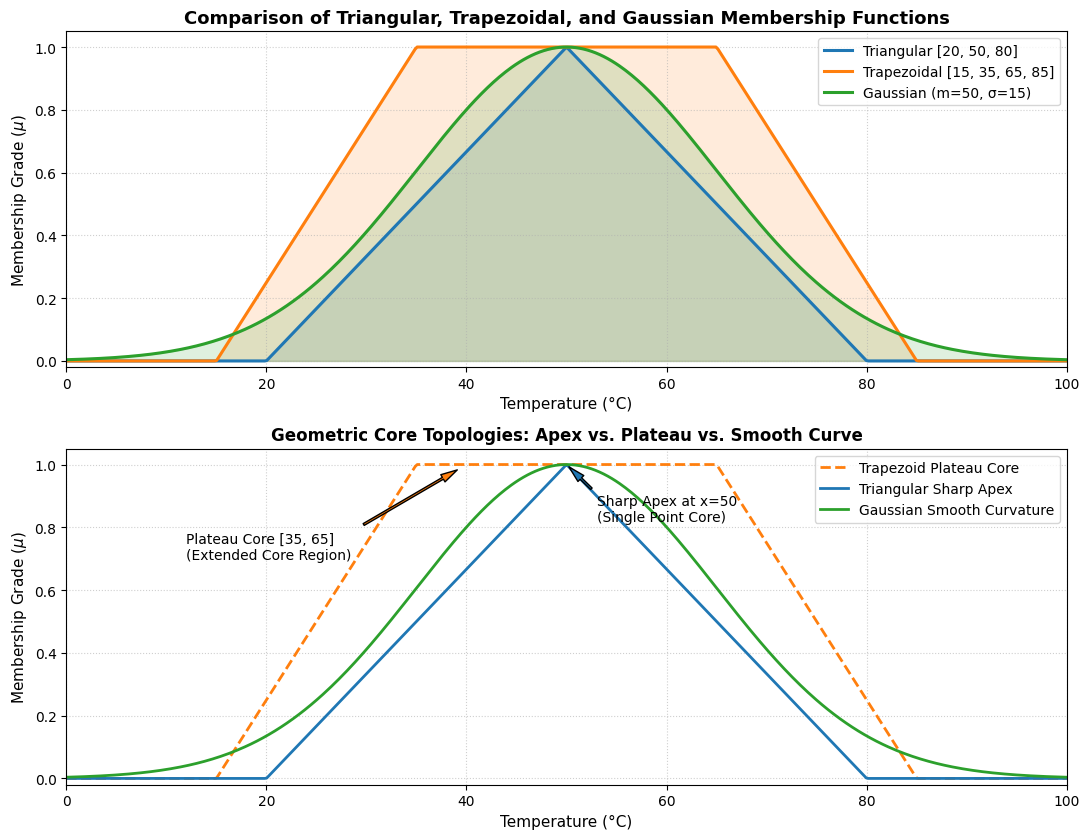

In [3]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8.5))

# Subplot 1: Individual Subplots overlaid with fills
ax1.plot(x_temp, mf_tri, color='#1f77b4', linewidth=2.2, label='Triangular [20, 50, 80]')
ax1.fill_between(x_temp, mf_tri, color='#1f77b4', alpha=0.15)

ax1.plot(x_temp, mf_trap, color='#ff7f0e', linewidth=2.2, label='Trapezoidal [15, 35, 65, 85]')
ax1.fill_between(x_temp, mf_trap, color='#ff7f0e', alpha=0.15)

ax1.plot(x_temp, mf_gauss, color='#2ca02c', linewidth=2.2, label='Gaussian (m=50, σ=15)')
ax1.fill_between(x_temp, mf_gauss, color='#2ca02c', alpha=0.15)

ax1.set_title('Comparison of Triangular, Trapezoidal, and Gaussian Membership Functions', fontsize=13, fontweight='bold')
ax1.set_xlabel('Temperature (°C)', fontsize=11)
ax1.set_ylabel(r'Membership Grade ($\mu$)', fontsize=11)
ax1.set_xlim(0, 100)
ax1.set_ylim(-0.02, 1.05)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True)

# Subplot 2: Geometric features and Plateau / Peak Annotations
ax2.plot(x_temp, mf_trap, color='#ff7f0e', linewidth=2, linestyle='--', label='Trapezoid Plateau Core')
ax2.plot(x_temp, mf_tri, color='#1f77b4', linewidth=2, label='Triangular Sharp Apex')
ax2.plot(x_temp, mf_gauss, color='#2ca02c', linewidth=2, label='Gaussian Smooth Curvature')

# Annotate apex and plateau
ax2.annotate('Sharp Apex at x=50\n(Single Point Core)', xy=(50, 1.0), xytext=(53, 0.82),
             arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=6))
ax2.annotate('Plateau Core [35, 65]\n(Extended Core Region)', xy=(40, 1.0), xytext=(12, 0.70),
             arrowprops=dict(facecolor='#ff7f0e', shrink=0.08, width=1.5, headwidth=6))

ax2.set_title('Geometric Core Topologies: Apex vs. Plateau vs. Smooth Curve', fontsize=12, fontweight='bold')
ax2.set_xlabel('Temperature (°C)', fontsize=11)
ax2.set_ylabel(r'Membership Grade ($\mu$)', fontsize=11)
ax2.set_xlim(0, 100)
ax2.set_ylim(-0.02, 1.05)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Function Type | Parameters | Core Region ($\mu = 1$) | Support Boundary ($\mu > 0$) | Mathematical Characteristics |
| :---: | :---: | :---: | :---: | :--- |
| **Triangular** | $a=20, b=50, c=80$ | Single point $\{50\}$ | $(20, 80)$ | Piecewise linear, lowest computational cost |
| **Trapezoidal** | $a=15, b=35, c=65, d=85$ | Interval $[35, 65]$ | $(15, 85)$ | Flat plateau core; models tolerance ranges |
| **Gaussian** | $m=50, \sigma=15$ | Single point $\{50\}$ | $(-\infty, \infty)$ | Infinitely smooth, continuously differentiable |

#### Key Observations in Simple Words:
1. **Computational Efficiency:** Triangular and trapezoidal MFs rely solely on linear interpolation, making them ideal for high-speed embedded real-time microcontrollers.
2. **Smoothness vs. Sharp Transitions:** The Gaussian function has continuous derivatives at all points, preventing abrupt derivative spikes in gradient-based neuro-fuzzy learning (such as ANFIS).
3. **Core Flexibility:** The trapezoidal MF allows an entire sub-range of inputs (here $[35, 65]^\circ\text{C}$) to be treated as completely optimal ($\mu = 1.0$).

---
### 7. Conclusion
1. We successfully constructed and evaluated Triangular, Trapezoidal, and Gaussian membership functions in Python using `scikit-fuzzy`.
2. We verified that our analytical equations match `scikit-fuzzy` output with numerical machine precision.
3. We compared and highlighted the structural differences between point cores, interval plateau cores, and smooth bell-shaped distributions.